# Pelacakan Objek Sederhana: *Template Matching* dan *Optical Flow* pada Dua Video

| | |
|---|---|
| **Nama** | Elsa Aiziyah |
| **NIM** | 25/572243/PPA/07187 |
| **Program** | Magister Kecerdasan Artifisial, Universitas Gadjah Mada |
| **Mata kuliah** | Computer Vision |

Notebook ini mengimplementasikan dua algoritma pelacakan sederhana, lalu membandingkannya pada dua video yang berbeda:

1. **Template-based tracking**: mencari kembali templat awal di sekitar posisi sebelumnya dengan `cv2.matchTemplate`.
2. **Visual tracking by optical flow**: melacak titik sudut Shi–Tomasi dengan Lucas–Kanade piramida, lalu menggeser dan menskalakan kotak dengan median aliran titik.

| Video | Sekuens | Kondisi kamera | Durasi yang dipakai |
|---|---|---|---|
| V1 | FaceOcc2 (OTB-100) | diam | 812 frame, 32,5 detik |
| V2 | David (OTB-100) | bergerak (dipegang tangan) | 471 frame beranotasi, 18,8 detik |

Kedua video memiliki anotasi kotak sasaran pada setiap frame (*ground truth*, GT), sehingga hasil dapat diukur secara kuantitatif. Kotak pada frame pertama diambil dari GT sebagai inisialisasi kedua pelacak, sesuai protokol OTB. Seluruh notebook berjalan dengan **Run all**, mengunduh datanya sendiri, dan menyimpan keluaran (video, gambar, CSV, JSON) di folder `keluaran_tracking`.

**Sumber data.** Wu, Y., Lim, J., & Yang, M.-H. (2013). *Online object tracking: A benchmark*. IEEE CVPR. Berkas diunduh dari repositori `opencv/opencv_extra` pada commit tetap dan diverifikasi dengan SHA-256.

## 1. Persiapan

Sel berikut memuat pustaka. Seed acak ditetapkan agar hasil dapat diulang.

In [1]:
import os, sys, time, json, hashlib, subprocess, urllib.request
import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt

cv2.setRNGSeed(0)
np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": 0.25})
print("OpenCV", cv2.__version__, "| NumPy", np.__version__, "| Pandas", pd.__version__)

OpenCV 5.0.0 | NumPy 2.4.6 | Pandas 2.2.3


Folder kerja ditentukan secara otomatis: `/content` bila dijalankan di Google Colab, atau `./content_lokal` bila dijalankan di komputer lokal.

In [2]:
BASE = "/content" if os.path.isdir("/content") else os.path.abspath("./content_lokal")
DIR_DATA = os.path.join(BASE, "data_tracking")
DIR_OUT = os.path.join(BASE, "keluaran_tracking")
os.makedirs(DIR_DATA, exist_ok=True)
os.makedirs(DIR_OUT, exist_ok=True)
print("Data   :", DIR_DATA)
print("Keluaran:", DIR_OUT)

Data   : /content/data_tracking
Keluaran: /content/keluaran_tracking


## 2. Data

Empat berkas diunduh dari commit tetap `c9cdf09` dan diperiksa hash SHA-256-nya: dua video (`.webm`) dan dua berkas anotasi (`gt.txt`, format `x,y,lebar,tinggi` per frame).

Pada **V2 (David)**, anotasi baru tersedia mulai frame ke-300 (penomoran dari 1) pada video 770 frame. Karena itu hanya segmen beranotasi yang dipakai, yaitu indeks frame 299 sampai 769 (nomor dari 0), sepanjang 471 frame. Penyelarasan indeks ini diperiksa dengan menumpangkan kotak GT pada frame: dengan indeks 299 kotak tepat berada pada wajah, sedangkan dengan indeks 300 kotak sedikit bergeser.

In [3]:
COMMIT = "c9cdf09e4d4e5e73effeabce97ef52a5c2789afc"   # commit tetap opencv/opencv_extra
RAW = f"https://raw.githubusercontent.com/opencv/opencv_extra/{COMMIT}/testdata/cv/tracking"
BERKAS = {
    "faceocc2.webm": ("faceocc2/data/faceocc2.webm", "5ffedeca4fb3acfd65e6f6aa71f016f748628727be1e24914fde2198b42089c5"),
    "gt_faceocc2.txt": ("faceocc2/gt.txt", "7d7b2dc7251e20fbb2fedfc36356ffbc7146ce59f49c21dfe251b8714b87ab88"),
    "david.webm": ("david/data/david.webm", "4bbe69b7d097379af4d7ad128f02692820dc57a6d8275ea2b9e7eef4399a3e61"),
    "gt_david.txt": ("david/gt.txt", "8e46f079b39f7877f9650bcf2fc42879b03f22d77ef832ca1d3e1ed258269588"),
}


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for blok in iter(lambda: f.read(1 << 20), b""):
            h.update(blok)
    return h.hexdigest()


for nama, (rel, hash_ref) in BERKAS.items():
    tujuan = os.path.join(DIR_DATA, nama)
    if not (os.path.exists(tujuan) and sha256(tujuan) == hash_ref):
        urllib.request.urlretrieve(f"{RAW}/{rel}", tujuan)
    assert sha256(tujuan) == hash_ref, f"Hash {nama} tidak cocok"
    print(f"{nama:18s} OK  {os.path.getsize(tujuan)/1e6:6.2f} MB")

faceocc2.webm      OK    4.13 MB
gt_faceocc2.txt    OK    0.01 MB
david.webm         OK    3.92 MB
gt_david.txt       OK    0.01 MB


In [4]:
# V1 memakai seluruh frame; V2 memakai segmen beranotasi (frame ke-299 dan seterusnya, indeks dari 0).
VIDEO = {
    "V1": dict(nama="FaceOcc2", kamera="diam", berkas="faceocc2.webm", gt="gt_faceocc2.txt", mulai=0),
    "V2": dict(nama="David", kamera="bergerak", berkas="david.webm", gt="gt_david.txt", mulai=299),
}


def baca_video(path):
    cap = cv2.VideoCapture(path)
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame = []
    while True:
        ok, f = cap.read()
        if not ok:
            break
        frame.append(f)
    cap.release()
    return frame, fps


DATA = {}
for k, v in VIDEO.items():
    semua, fps = baca_video(os.path.join(DIR_DATA, v["berkas"]))
    gt = np.loadtxt(os.path.join(DIR_DATA, v["gt"]), delimiter=",").astype(float)
    bgr = semua[v["mulai"]: v["mulai"] + len(gt)]
    assert len(bgr) == len(gt), (k, len(bgr), len(gt))
    gray = [cv2.cvtColor(f, cv2.COLOR_BGR2GRAY) for f in bgr]
    DATA[k] = dict(bgr=bgr, gray=gray, gt=gt, fps=fps)
    h, w = gray[0].shape
    print(f"{k} {v['nama']:9s} kamera {v['kamera']:8s}: {len(gt)} frame, {w}x{h}, {fps:.0f} FPS, durasi {len(gt)/fps:.1f} s, "
          f"lebar kotak {gt[:,2].min():.0f}-{gt[:,2].max():.0f} px")

V1 FaceOcc2  kamera diam    : 812 frame, 320x240, 25 FPS, durasi 32.5 s, lebar kotak 58-92 px
V2 David     kamera bergerak: 471 frame, 320x240, 25 FPS, durasi 18.8 s, lebar kotak 24-70 px


Berikut frame pertama kedua video beserta kotak GT yang menjadi inisialisasi pelacak.

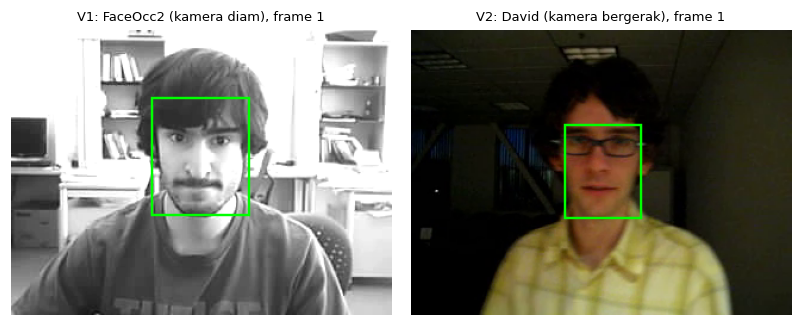

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(7.4, 2.9))
for a_, (k, v) in zip(ax, VIDEO.items()):
    f = cv2.cvtColor(DATA[k]["bgr"][0], cv2.COLOR_BGR2RGB)
    x, y, w, h = DATA[k]["gt"][0]
    a_.imshow(f)
    a_.add_patch(plt.Rectangle((x, y), w, h, fill=False, ec="lime", lw=1.6))
    a_.set_title(f"{k}: {v['nama']} (kamera {v['kamera']}), frame 1", fontsize=8.5)
    a_.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(DIR_OUT, "fig_sampel.png"), dpi=200, bbox_inches="tight")
plt.show()

## 3. Metode 1: Template-based tracking

Templat $T$ adalah potongan citra pada kotak GT di frame pertama. Pada frame berikutnya, templat dicocokkan di **jendela pencarian** yang berpusat pada kotak sebelumnya dan diperlebar sebesar `margin` (bawaan 0,6) kali ukuran kotak pada setiap sisi. Skor kecocokan yang dipakai adalah korelasi silang ternormalisasi berpusat nol (`TM_CCOEFF_NORMED`):

$$
R(x,y)=\frac{\sum_{x',y'}\big(T'(x',y')\cdot I'(x+x',y+y')\big)}{\sqrt{\sum_{x',y'}T'(x',y')^2\cdot\sum_{x',y'}I'(x+x',y+y')^2}},
$$

dengan $T'$ dan $I'$ adalah $T$ dan citra $I$ setelah dikurangi rerata masing-masing. Posisi dengan $R$ terbesar menjadi posisi kotak baru. Normalisasi ini membuat skor tidak berubah terhadap penambahan dan penskalaan kecerahan seragam. Ukuran kotak **tetap**, dan pada pengaturan bawaan templat **tidak diperbarui** (varian dengan pembaruan diuji pada bagian 8).

## 4. Metode 2: Visual tracking by optical flow

Pada frame pertama, titik sudut Shi–Tomasi (maksimum 100) dipilih di dalam kotak. Untuk setiap frame baru:

1. Titik dilacak dengan Lucas–Kanade piramida (jendela 21×21, tiga tingkat piramida).
2. **Uji maju–mundur**: titik dilacak kembali ke frame sebelumnya, dan titik dengan galat $\lVert p-\hat p\rVert \ge 1{,}5$ piksel dibuang.
3. **Pergeseran** kotak adalah median pergeseran titik yang lolos, dan **skala** adalah median rasio jarak antarpasangan titik (dibatasi 0,9–1,1 per frame).
4. Titik yang keluar dari kotak (diperlebar 15%) dibuang. Bila titik tersisa kurang dari 15, sudut baru dicari di dalam kotak.

Bila titik yang lolos kurang dari 3, kotak tidak digeser pada frame itu.

## 5. Metrik evaluasi

Mengikuti protokol OTB, dengan $B_p$ kotak prediksi dan $B_g$ kotak GT:

$$
\mathrm{IoU}=\frac{|B_p\cap B_g|}{|B_p\cup B_g|},\qquad
\mathrm{CLE}=\lVert c_p-c_g\rVert_2 ,
$$

dengan $c$ pusat kotak. **Presisi@20** adalah proporsi frame dengan CLE ≤ 20 piksel. **Kurva keberhasilan** adalah proporsi frame dengan IoU di atas ambang $\tau\in[0,1]$, dan **AUC** adalah rata-rata kurva itu pada 101 ambang. **Sukses50** adalah proporsi frame dengan IoU > 0,5. **FPS** dihitung dari waktu pemanggilan `update` saja (tanpa pembacaan video dan penggambaran) pada mesin yang menjalankan notebook, sehingga bernilai relatif dan bergantung perangkat.

Fungsi metrik diuji lebih dahulu pada kasus yang jawabannya dapat dihitung manual.

In [6]:
def klip_kotak(b, lebar, tinggi):
    x, y, w, h = b
    x = min(max(x, 0), lebar - 1)
    y = min(max(y, 0), tinggi - 1)
    w = min(w, lebar - x)
    h = min(h, tinggi - y)
    return x, y, w, h


class TrackerTemplate:
    """Template matching pada jendela pencarian di sekitar posisi sebelumnya.

    Templat diambil dari kotak awal dan tidak berubah (perbarui=False), atau
    diperbarui bila skor kecocokan >= ambang (perbarui=True).
    """

    def __init__(self, metode=cv2.TM_CCOEFF_NORMED, margin=0.6, perbarui=False, ambang=0.8):
        self.metode, self.margin, self.perbarui, self.ambang = metode, margin, perbarui, ambang
        self.skor = []

    def init(self, gray, kotak):
        self.H, self.W = gray.shape
        x, y, w, h = [int(round(v)) for v in kotak]
        self.w, self.h = w, h
        self.x, self.y = x, y
        self.templat = gray[y:y + h, x:x + w].copy()
        self.skor = [1.0]

    def update(self, gray):
        m = self.margin
        x0 = int(max(0, self.x - m * self.w))
        y0 = int(max(0, self.y - m * self.h))
        x1 = int(min(self.W, self.x + self.w + m * self.w))
        y1 = int(min(self.H, self.y + self.h + m * self.h))
        area = gray[y0:y1, x0:x1]
        if area.shape[0] < self.h or area.shape[1] < self.w:
            self.skor.append(np.nan)
            return (self.x, self.y, self.w, self.h)
        res = cv2.matchTemplate(area, self.templat, self.metode)
        mn, mx, lmn, lmx = cv2.minMaxLoc(res)
        if self.metode in (cv2.TM_SQDIFF, cv2.TM_SQDIFF_NORMED):
            loc, s = lmn, 1.0 - mn          # skor dibalik agar "makin besar makin cocok"
        else:
            loc, s = lmx, mx
        self.x, self.y = x0 + loc[0], y0 + loc[1]
        self.skor.append(float(s))
        if self.perbarui and s >= self.ambang:
            self.templat = gray[self.y:self.y + self.h, self.x:self.x + self.w].copy()
        return (self.x, self.y, self.w, self.h)

    def titik(self):
        return None

In [7]:
class TrackerAliranOptik:
    """Pelacak berbasis aliran optik jarang: Shi-Tomasi + Lucas-Kanade piramida,
    uji maju-mundur, lalu pergeseran dan skala kotak dari median seluruh titik."""

    def __init__(self, maks_titik=100, min_titik=15, galat_fb=1.5, jendela=(21, 21), tingkat=3, pakai_skala=True):
        self.maks_titik, self.min_titik, self.galat_fb = maks_titik, min_titik, galat_fb
        self.lk = dict(winSize=jendela, maxLevel=tingkat,
                       criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01))
        self.pakai_skala = pakai_skala
        self.jumlah_titik = []

    def _sudut(self, gray, kotak, titik_lama=None):
        x, y, w, h = [int(round(v)) for v in kotak]
        mask = np.zeros(gray.shape, np.uint8)
        mask[max(y, 0):y + h, max(x, 0):x + w] = 255
        if titik_lama is not None:
            for px, py in titik_lama.reshape(-1, 2):
                cv2.circle(mask, (int(px), int(py)), 3, 0, -1)
        p = cv2.goodFeaturesToTrack(gray, self.maks_titik, 0.01, 3, mask=mask, blockSize=5)
        return p if p is not None else np.empty((0, 1, 2), np.float32)

    def init(self, gray, kotak):
        self.prev = gray
        self.kotak = [float(v) for v in kotak]
        self.p = self._sudut(gray, self.kotak)
        self.jumlah_titik = [len(self.p)]

    def update(self, gray):
        x, y, w, h = self.kotak
        if len(self.p) >= 2:
            p1, st, _ = cv2.calcOpticalFlowPyrLK(self.prev, gray, self.p, None, **self.lk)
            p0r, st2, _ = cv2.calcOpticalFlowPyrLK(gray, self.prev, p1, None, **self.lk)
            fb = np.linalg.norm((self.p - p0r).reshape(-1, 2), axis=1)
            ok = (st[:, 0] == 1) & (st2[:, 0] == 1) & (fb < self.galat_fb)
            a, b = self.p[ok].reshape(-1, 2), p1[ok].reshape(-1, 2)
        else:
            a = b = np.empty((0, 2), np.float32)
        if len(a) >= 3:
            d = np.median(b - a, axis=0)
            s = 1.0
            if self.pakai_skala and len(a) >= 5:
                n = len(a)
                i, j = np.triu_indices(n, 1)
                if len(i) > 300:
                    pilih = np.random.RandomState(0).choice(len(i), 300, replace=False)
                    i, j = i[pilih], j[pilih]
                d0 = np.linalg.norm(a[i] - a[j], axis=1)
                d1 = np.linalg.norm(b[i] - b[j], axis=1)
                v = d0 > 1e-3
                if v.any():
                    s = float(np.clip(np.median(d1[v] / d0[v]), 0.9, 1.1))
            cx, cy = x + w / 2 + d[0], y + h / 2 + d[1]
            w, h = w * s, h * s
            x, y = cx - w / 2, cy - h / 2
            self.kotak = [x, y, w, h]
            # buang titik yang keluar dari kotak yang diperlebar
            dalam = (b[:, 0] > x - 0.15 * w) & (b[:, 0] < x + 1.15 * w) & (b[:, 1] > y - 0.15 * h) & (b[:, 1] < y + 1.15 * h)
            b = b[dalam]
        else:
            b = np.empty((0, 2), np.float32)           # kehilangan titik; kotak tidak bergerak
        pb = b.reshape(-1, 1, 2).astype(np.float32)
        if len(pb) < self.min_titik:
            baru = self._sudut(gray, self.kotak, pb if len(pb) else None)
            pb = np.concatenate([pb, baru], axis=0) if len(pb) else baru
        self.p, self.prev = pb, gray
        self.jumlah_titik.append(len(pb))
        return tuple(self.kotak)

    def titik(self):
        return self.p.reshape(-1, 2)

In [8]:
def iou_xywh(a, b):
    ax1, ay1, ax2, ay2 = a[:, 0], a[:, 1], a[:, 0] + a[:, 2], a[:, 1] + a[:, 3]
    bx1, by1, bx2, by2 = b[:, 0], b[:, 1], b[:, 0] + b[:, 2], b[:, 1] + b[:, 3]
    iw = np.clip(np.minimum(ax2, bx2) - np.maximum(ax1, bx1), 0, None)
    ih = np.clip(np.minimum(ay2, by2) - np.maximum(ay1, by1), 0, None)
    inter = iw * ih
    uni = a[:, 2] * a[:, 3] + b[:, 2] * b[:, 3] - inter
    return inter / np.maximum(uni, 1e-9)


def cle_xywh(a, b):
    return np.linalg.norm((a[:, :2] + a[:, 2:] / 2) - (b[:, :2] + b[:, 2:] / 2), axis=1)


AMBANG_IOU = np.linspace(0, 1, 101)


def evaluasi(pred, gt, waktu):
    iou, cle = iou_xywh(pred, gt), cle_xywh(pred, gt)
    kurva = np.array([(iou > t).mean() for t in AMBANG_IOU])
    return dict(
        CLE_rata=cle.mean(), CLE_median=np.median(cle), RMSE=np.sqrt((cle ** 2).mean()),
        Presisi20=(cle <= 20).mean(), AUC=kurva.mean(), Sukses50=(iou > 0.5).mean(),
        IoU_rata=iou.mean(), FPS=len(pred) / max(waktu, 1e-9),
    ), iou, cle, kurva

In [9]:
# Uji kebenaran fungsi metrik pada kasus yang jawabannya diketahui.
a = np.array([[0, 0, 10, 10]], float)
assert abs(iou_xywh(a, a)[0] - 1.0) < 1e-12
assert abs(iou_xywh(a, np.array([[5, 0, 10, 10]], float))[0] - 50 / 150) < 1e-12   # irisan 50, gabungan 150
assert iou_xywh(a, np.array([[20, 20, 5, 5]], float))[0] == 0
assert abs(cle_xywh(a, np.array([[3, 4, 10, 10]], float))[0] - 5.0) < 1e-12        # selisih (3,4) -> 5
assert abs(cle_xywh(a, np.array([[0, 0, 20, 20]], float))[0] - 5 * np.sqrt(2)) < 1e-12
print("Uji metrik lulus.")

Uji metrik lulus.


## 6. Menjalankan kedua pelacak pada kedua video

Pengaturan bawaan ditetapkan **sebelum** evaluasi dan tidak disesuaikan terhadap kedua video ini. Pengaruh perubahan pengaturan dilaporkan terpisah pada bagian 8.

In [10]:
def jalankan(tracker, kunci, simpan_titik=False):
    d = DATA[kunci]
    gray, gt = d["gray"], d["gt"]
    tracker.init(gray[0], gt[0])
    pred = [tuple(gt[0])]
    titik = [tracker.titik()] if simpan_titik else None
    t_total = 0.0
    for i in range(1, len(gray)):
        t0 = time.perf_counter()
        b = tracker.update(gray[i])
        t_total += time.perf_counter() - t0
        pred.append(tuple(float(v) for v in b))
        if simpan_titik:
            titik.append(None if tracker.titik() is None else tracker.titik().copy())
    return np.array(pred, float), t_total, titik


METODE = {
    "Template": lambda: TrackerTemplate(),
    "Aliran optik": lambda: TrackerAliranOptik(),
}

HASIL = {}      # (video, metode) -> dict
for k in VIDEO:
    for m, buat in METODE.items():
        tr = buat()
        pred, t, titik = jalankan(tr, k, simpan_titik=True)
        met, iou, cle, kurva = evaluasi(pred, DATA[k]["gt"], t)
        HASIL[(k, m)] = dict(pred=pred, iou=iou, cle=cle, kurva=kurva, met=met, titik=titik, tracker=tr)

In [11]:
baris = []
for (k, m), r in HASIL.items():
    baris.append(dict(Video=f"{k} {VIDEO[k]['nama']} ({VIDEO[k]['kamera']})", Metode=m, **r["met"]))
TABEL = pd.DataFrame(baris)
TABEL

,Video,Metode,CLE_rata,CLE_median,RMSE,Presisi20,AUC,Sukses50,IoU_rata,FPS
0,V1 FaceOcc2 (diam),Template,10.436993,6.184658,13.537566,0.775862,0.710920,0.899015,0.713180,1113.293030
1,V1 FaceOcc2 (diam),Aliran optik,51.585664,19.988425,78.267416,0.500000,0.472663,0.559113,0.473776,179.682506
2,V2 David (bergerak),Template,63.551060,69.602442,75.270796,0.191083,0.182927,0.188960,0.182596,835.505885
3,V2 David (bergerak),Aliran optik,5.595692,5.414595,6.000684,1.000000,0.638015,0.859873,0.639378,88.262463


In [12]:
pd.set_option("display.width", 200)
fmt = TABEL.copy()
for c in ("CLE_rata", "CLE_median", "RMSE", "FPS"):
    fmt[c] = fmt[c].round(1)
for c in ("Presisi20", "AUC", "Sukses50", "IoU_rata"):
    fmt[c] = fmt[c].round(3)
fmt

,Video,Metode,CLE_rata,CLE_median,RMSE,Presisi20,AUC,Sukses50,IoU_rata,FPS
0,V1 FaceOcc2 (diam),Template,10.4,6.2,13.5,0.776,0.711,0.899,0.713,1113.3
1,V1 FaceOcc2 (diam),Aliran optik,51.6,20.0,78.3,0.500,0.473,0.559,0.474,179.7
2,V2 David (bergerak),Template,63.6,69.6,75.3,0.191,0.183,0.189,0.183,835.5
3,V2 David (bergerak),Aliran optik,5.6,5.4,6.0,1.000,0.638,0.860,0.639,88.3


## 7. Analisis hasil

### 7.1 Galat per frame dan kurva keberhasilan

Area kuning pada gambar pertama menandai segmen yang dianalisis pada tabel berikutnya.

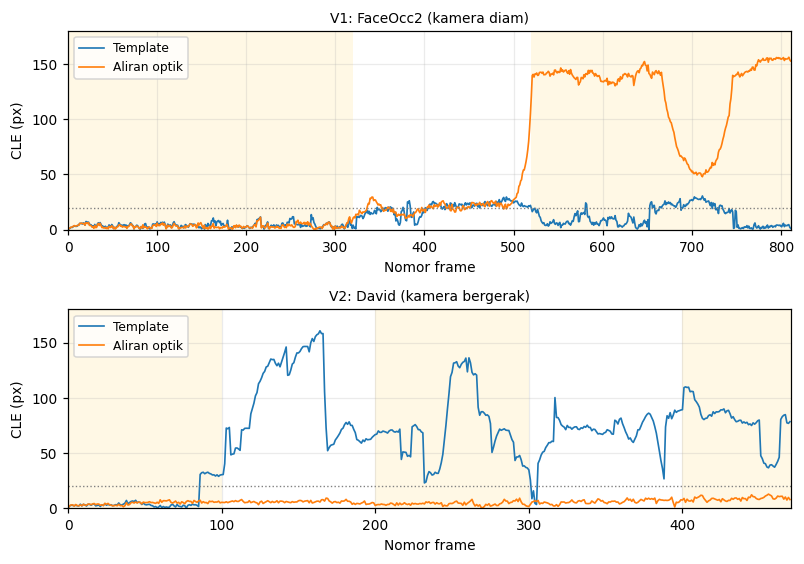

In [13]:
WARNA = {"Template": "#1f77b4", "Aliran optik": "#ff7f0e"}
SEGMEN = {
    "V1": [("A: wajah frontal, buku muncul", 0, 319), ("B: kepala miring, buku di samping", 320, 519), ("C: topi, tangan, buku dari bawah", 520, 811)],
    "V2": [("0-99", 0, 99), ("100-199", 100, 199), ("200-299", 200, 299), ("300-399", 300, 399), ("400-470", 400, 470)],
}
fig, ax = plt.subplots(2, 1, figsize=(7.4, 5.2))
for a_, k in zip(ax, VIDEO):
    for m in METODE:
        a_.plot(HASIL[(k, m)]["cle"], color=WARNA[m], lw=1.1, label=m)
    a_.axhline(20, color="gray", ls=":", lw=0.9)
    for i, (_, s, e) in enumerate(SEGMEN[k]):
        if i % 2 == 0:
            a_.axvspan(s, e + 1, color="#fff2cc", alpha=0.5, lw=0)
    a_.set_ylabel("CLE (px)")
    a_.set_xlabel("Nomor frame")
    a_.set_title(f"{k}: {VIDEO[k]['nama']} (kamera {VIDEO[k]['kamera']})", fontsize=9)
    a_.set_xlim(0, len(DATA[k]["gt"]))
    a_.set_ylim(0, 180)
    a_.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(DIR_OUT, "fig_cle.png"), dpi=200)
plt.show()

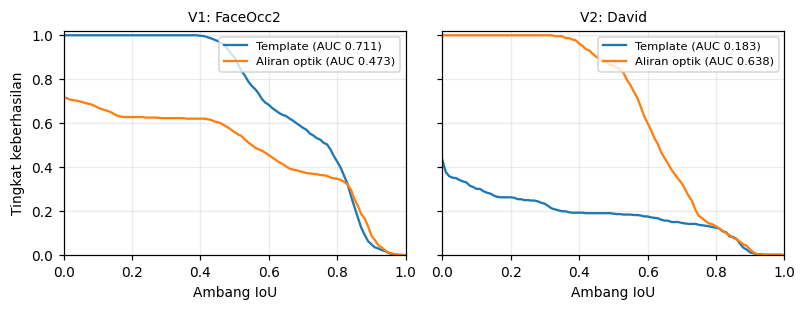

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(7.4, 2.9), sharey=True)
for a_, k in zip(ax, VIDEO):
    for m in METODE:
        r = HASIL[(k, m)]
        a_.plot(AMBANG_IOU, r["kurva"], color=WARNA[m], label=f"{m} (AUC {r['met']['AUC']:.3f})")
    a_.set_xlabel("Ambang IoU")
    a_.set_title(f"{k}: {VIDEO[k]['nama']}", fontsize=9)
    a_.legend(fontsize=7.5, loc="upper right")
    a_.set_xlim(0, 1)
    a_.set_ylim(0, 1.02)
ax[0].set_ylabel("Tingkat keberhasilan")
plt.tight_layout()
plt.savefig(os.path.join(DIR_OUT, "fig_kurva.png"), dpi=200)
plt.show()

### 7.2 Hasil per segmen dan saat pelacak kehilangan sasaran

Pada V1, segmen ditentukan dari pengamatan frame: **A** (frame 0–319), wajah menghadap kamera dengan buku yang muncul dua kali; **B** (320–519), kepala miring dengan buku di sisi wajah; **C** (520–811), topi, tangan di kepala, dan buku dari arah bawah. Pada V2, segmen adalah blok sekitar 100 frame. "Kehilangan" didefinisikan sebagai rentetan pertama sedikitnya 25 frame berturut-turut dengan IoU < 0,1.

In [15]:
def tabel_segmen():
    baris = []
    for k in VIDEO:
        for nama, s, e in SEGMEN[k]:
            r = dict(Video=k, Segmen=f"{nama} ({s}-{e})")
            for m in METODE:
                r[f"CLE {m} (px)"] = HASIL[(k, m)]["cle"][s:e + 1].mean()
                r[f"IoU {m}"] = HASIL[(k, m)]["iou"][s:e + 1].mean()
            baris.append(r)
    return pd.DataFrame(baris)


TAB_SEG = tabel_segmen()
TAB_SEG.round(2)

,Video,Segmen,CLE Template (px),IoU Template,CLE Aliran optik (px),IoU Aliran optik
0,V1,"A: wajah frontal, buku muncul (0-319)",3.91,0.84,3.21,0.86
1,V1,"B: kepala miring, buku di samping (320-519)",19.22,0.55,22.90,0.52
2,V1,"C: topi, tangan, buku dari bawah (520-811)",11.58,0.68,124.24,0.02
3,V2,0-99 (0-99),6.81,0.74,4.48,0.82
4,V2,100-199 (100-199),97.13,0.01,5.72,0.69
5,V2,200-299 (200-299),72.76,0.06,4.08,0.61
6,V2,300-399 (300-399),67.42,0.04,5.88,0.57
7,V2,400-470 (400-470),77.74,0.02,8.73,0.45


In [16]:
def awal_hilang(iou, n=25, ambang=0.1):
    """Frame awal dari rentetan pertama sedikitnya n frame berturut-turut dengan IoU < ambang."""
    rendah, run = iou < ambang, 0
    for i, v in enumerate(rendah):
        run = run + 1 if v else 0
        if run >= n:
            return i - n + 1
    return None


baris = []
for (k, m), r in HASIL.items():
    f = awal_hilang(r["iou"])
    baris.append(dict(Video=k, Metode=m, Frame_hilang=f, Detik=None if f is None else round(f / DATA[k]["fps"], 1),
                      Persen_IoU_nol=round(float((r["iou"] == 0).mean()) * 100, 1)))
TAB_HILANG = pd.DataFrame(baris)
for k in VIDEO:
    sk = np.array(HASIL[(k, "Template")]["tracker"].skor[1:], float)
    print(f"{k} skor kecocokan templat: median {np.nanmedian(sk):.2f}, persentil 5-95 = {np.nanpercentile(sk, 5):.2f}-{np.nanpercentile(sk, 95):.2f}")
TAB_HILANG

V1 skor kecocokan templat: median 0.52, persentil 5-95 = 0.33-0.85
V2 skor kecocokan templat: median 0.54, persentil 5-95 = 0.41-0.77


,Video,Metode,Frame_hilang,Detik,Persen_IoU_nol
0,V1,Template,NaN,NaN,0.0
1,V1,Aliran optik,514.0,20.6,28.2
2,V2,Template,103.0,4.1,56.7
3,V2,Aliran optik,NaN,NaN,0.0


### 7.3 Ukuran kotak

Template matching memakai ukuran tetap, sedangkan aliran optik memperkirakan skala. Gambar berikut membandingkan lebar kotak dengan GT.

V2 aliran optik, lebar prediksi / lebar GT: frame 1 = 1.00, frame 450 = 1.46, maksimum = 1.74


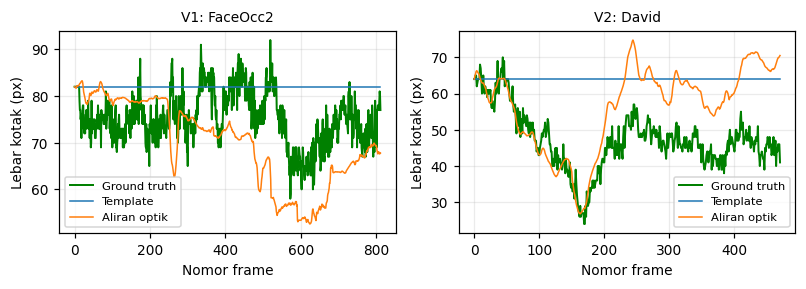

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(7.4, 2.7))
for a_, k in zip(ax, VIDEO):
    gt = DATA[k]["gt"]
    a_.plot(gt[:, 2], color="green", lw=1.3, label="Ground truth")
    for m in METODE:
        a_.plot(HASIL[(k, m)]["pred"][:, 2], color=WARNA[m], lw=1.0, label=m)
    a_.set_xlabel("Nomor frame")
    a_.set_ylabel("Lebar kotak (px)")
    a_.set_title(f"{k}: {VIDEO[k]['nama']}", fontsize=9)
    a_.legend(fontsize=7.5)
plt.tight_layout()
r_lebar = HASIL[("V2", "Aliran optik")]["pred"][:, 2] / DATA["V2"]["gt"][:, 2]
print(f"V2 aliran optik, lebar prediksi / lebar GT: frame 1 = {r_lebar[0]:.2f}, frame 450 = {r_lebar[449]:.2f}, maksimum = {r_lebar.max():.2f}")
plt.savefig(os.path.join(DIR_OUT, "fig_ukuran.png"), dpi=200)
plt.show()

## 8. Sensitivitas terhadap pengaturan

Tiap baris mengubah **satu** pengaturan dari nilai bawaan. Tabel ini bersifat eksploratif: pengaturan diuji pada video yang sama dengan evaluasi, sehingga varian terbaik di tabel **tidak boleh** dianggap sebagai pengaturan yang akan berlaku pada video lain.

In [18]:
# Tiap varian mengubah satu pengaturan dari pengaturan bawaan. Pengaturan bawaan ditetapkan sebelum evaluasi.
VARIAN = [
    ("Template: TM_CCOEFF_NORMED (bawaan)", lambda: TrackerTemplate()),
    ("Template: TM_CCORR_NORMED", lambda: TrackerTemplate(metode=cv2.TM_CCORR_NORMED)),
    ("Template: TM_SQDIFF_NORMED", lambda: TrackerTemplate(metode=cv2.TM_SQDIFF_NORMED)),
    ("Template: margin 0,3", lambda: TrackerTemplate(margin=0.3)),
    ("Template: margin 1,0", lambda: TrackerTemplate(margin=1.0)),
    ("Template: templat diperbarui (skor >= 0,8)", lambda: TrackerTemplate(perbarui=True, ambang=0.8)),
    ("Template: templat diperbarui (skor >= 0,6)", lambda: TrackerTemplate(perbarui=True, ambang=0.6)),
    ("Aliran optik: bawaan", lambda: TrackerAliranOptik()),
    ("Aliran optik: tanpa skala", lambda: TrackerAliranOptik(pakai_skala=False)),
    ("Aliran optik: galat F-B 0,5 px", lambda: TrackerAliranOptik(galat_fb=0.5)),
    ("Aliran optik: galat F-B 3,0 px", lambda: TrackerAliranOptik(galat_fb=3.0)),
    ("Aliran optik: 50 titik", lambda: TrackerAliranOptik(maks_titik=50)),
    ("Aliran optik: 200 titik", lambda: TrackerAliranOptik(maks_titik=200)),
]
baris = []
for nama, buat in VARIAN:
    r = dict(Varian=nama)
    for k in VIDEO:
        pred, t, _ = jalankan(buat(), k)
        met, *_ = evaluasi(pred, DATA[k]["gt"], t)
        r[f"{k} AUC"], r[f"{k} CLE (px)"] = met["AUC"], met["CLE_rata"]
    baris.append(r)
TAB_SENS = pd.DataFrame(baris)
TAB_SENS.round(3)

,Varian,V1 AUC,V1 CLE (px),V2 AUC,V2 CLE (px)
0,Template: TM_CCOEFF_NORMED (bawaan),0.711,10.437,0.183,63.551
1,Template: TM_CCORR_NORMED,0.380,66.583,0.136,66.779
2,Template: TM_SQDIFF_NORMED,0.470,44.527,0.189,76.948
3,"Template: margin 0,3",0.711,10.437,0.200,69.265
4,"Template: margin 1,0",0.709,10.626,0.165,69.478
5,"Template: templat diperbarui (skor >= 0,8)",0.602,18.653,0.439,15.584
6,"Template: templat diperbarui (skor >= 0,6)",0.639,15.218,0.439,15.584
7,Aliran optik: bawaan,0.473,51.586,0.638,5.596
8,Aliran optik: tanpa skala,0.477,49.918,0.543,5.171
9,"Aliran optik: galat F-B 0,5 px",0.625,15.088,0.695,4.847


## 9. Video hasil dan cuplikan

Setiap video hasil menampilkan kotak GT (hijau), kotak Template (biru), kotak Aliran optik (oranye), titik fitur aliran optik (kuning), serta IoU masing-masing pada pita atas. Video diperbesar dua kali agar mudah dilihat.

In [19]:
SKALA = 2
BGR = {"Template": (255, 128, 0), "Aliran optik": (0, 128, 255)}


def gambar_frame(k, i):
    d = DATA[k]
    im = cv2.resize(d["bgr"][i], None, fx=SKALA, fy=SKALA, interpolation=cv2.INTER_CUBIC)

    def kotak(b, warna, tebal=2):
        x, y, w, h = [int(round(v * SKALA)) for v in b]
        cv2.rectangle(im, (x, y), (x + w, y + h), warna, tebal, cv2.LINE_AA)

    kotak(d["gt"][i], (0, 220, 0), 2)
    for m in METODE:
        kotak(HASIL[(k, m)]["pred"][i], BGR[m], 2)
    t = HASIL[(k, "Aliran optik")]["titik"][i]
    if t is not None:
        for px, py in t:
            cv2.circle(im, (int(round(px * SKALA)), int(round(py * SKALA))), 2, (0, 255, 255), -1, cv2.LINE_AA)
    band = np.zeros((34, im.shape[1], 3), np.uint8)
    cv2.putText(band, f"{VIDEO[k]['nama']} ({VIDEO[k]['kamera']})  frame {i + 1}/{len(d['gt'])}  t={i / d['fps']:.1f}s",
                (6, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 255), 1, cv2.LINE_AA)
    x0 = 6
    for nama, warna, teks in (("GT", (0, 220, 0), "GT"),
                              ("Template", BGR["Template"], f"Template IoU {HASIL[(k, 'Template')]['iou'][i]:.2f}"),
                              ("Aliran optik", BGR["Aliran optik"], f"Aliran optik IoU {HASIL[(k, 'Aliran optik')]['iou'][i]:.2f}")):
        cv2.rectangle(band, (x0, 21), (x0 + 10, 31), warna, -1)
        cv2.putText(band, teks, (x0 + 14, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
        x0 += 14 + 8 * len(teks) + 18
    return np.vstack([band, im])


def tulis_video(k, nama_berkas):
    n = len(DATA[k]["gt"])
    f0 = gambar_frame(k, 0)
    h, w = f0.shape[:2]
    path = os.path.join(DIR_OUT, nama_berkas)
    cmd = ["ffmpeg", "-y", "-loglevel", "error", "-f", "rawvideo", "-pix_fmt", "bgr24", "-s", f"{w}x{h}",
           "-r", str(int(DATA[k]["fps"])), "-i", "-", "-an", "-c:v", "libx264", "-preset", "veryfast",
           "-crf", "21", "-pix_fmt", "yuv420p", "-movflags", "+faststart", path]
    p = subprocess.Popen(cmd, stdin=subprocess.PIPE)
    for i in range(n):
        p.stdin.write(np.ascontiguousarray(gambar_frame(k, i)).tobytes())
    p.stdin.close()
    p.wait()
    assert p.returncode == 0
    cap = cv2.VideoCapture(path)
    nf, fps = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)), cap.get(cv2.CAP_PROP_FPS)
    cap.release()
    print(f"{nama_berkas}: {nf} frame, {fps:.0f} FPS, {nf / fps:.1f} s, {os.path.getsize(path) / 1e6:.1f} MB")


tulis_video("V1", "hasil_video1_kamera_diam.mp4")
tulis_video("V2", "hasil_video2_kamera_bergerak.mp4")

hasil_video1_kamera_diam.mp4: 812 frame, 25 FPS, 32.5 s, 5.8 MB
hasil_video2_kamera_bergerak.mp4: 471 frame, 25 FPS, 18.8 s, 3.6 MB


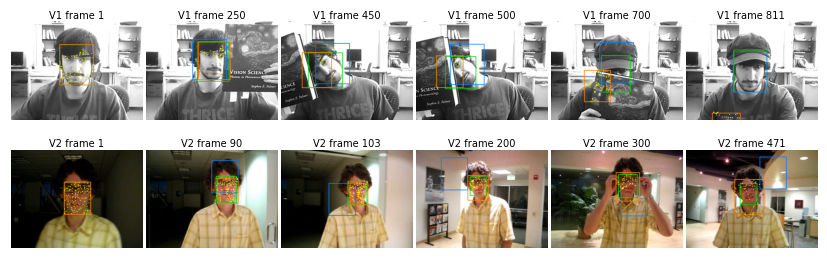

In [20]:
SNAP = {"V1": [1, 250, 450, 500, 700, 811], "V2": [1, 90, 103, 200, 300, 471]}
fig, ax = plt.subplots(2, 6, figsize=(7.4, 2.5))
for r, k in enumerate(VIDEO):
    for c, nomor in enumerate(SNAP[k]):
        a_ = ax[r, c]
        im = gambar_frame(k, nomor - 1)[34:]
        a_.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        a_.set_title(f"{k} frame {nomor}", fontsize=6.5, pad=2)
        a_.axis("off")
plt.subplots_adjust(wspace=0.03, hspace=0.02, left=0.005, right=0.995, top=0.93, bottom=0.005)
plt.savefig(os.path.join(DIR_OUT, "fig_snapshot.png"), dpi=220, bbox_inches="tight")
plt.show()

## 10. Ekspor hasil

In [21]:
baris = []
for k in VIDEO:
    for i in range(len(DATA[k]["gt"])):
        r = dict(video=k, frame=i + 1)
        for nm, v in zip("xywh", DATA[k]["gt"][i]):
            r[f"gt_{nm}"] = v
        for m, kode in (("Template", "tmpl"), ("Aliran optik", "of")):
            for nm, v in zip("xywh", HASIL[(k, m)]["pred"][i]):
                r[f"{kode}_{nm}"] = v
            r[f"{kode}_iou"], r[f"{kode}_cle"] = HASIL[(k, m)]["iou"][i], HASIL[(k, m)]["cle"][i]
        baris.append(r)
pd.DataFrame(baris).round(4).to_csv(os.path.join(DIR_OUT, "trajektori_per_frame.csv"), index=False)


def bersih(o):
    if isinstance(o, dict):
        return {str(k): bersih(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [bersih(v) for v in o]
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else float(o)
    if isinstance(o, (np.integer,)):
        return int(o)
    return o


ringkas = dict(
    metrik=TABEL.to_dict("records"), segmen=TAB_SEG.to_dict("records"), kehilangan=TAB_HILANG.to_dict("records"),
    sensitivitas=TAB_SENS.to_dict("records"),
    video={k: dict(nama=v["nama"], kamera=v["kamera"], frame=len(DATA[k]["gt"]), fps=DATA[k]["fps"],
                   durasi_detik=len(DATA[k]["gt"]) / DATA[k]["fps"]) for k, v in VIDEO.items()},
    versi=dict(opencv=cv2.__version__, numpy=np.__version__, pandas=pd.__version__, commit_data=COMMIT),
)
with open(os.path.join(DIR_OUT, "ringkasan_metrik.json"), "w") as f:
    json.dump(bersih(ringkas), f, indent=1, ensure_ascii=False)
print(sorted(os.listdir(DIR_OUT)))

['fig_cle.png', 'fig_kurva.png', 'fig_sampel.png', 'fig_snapshot.png', 'fig_ukuran.png', 'hasil_video1_kamera_diam.mp4', 'hasil_video2_kamera_bergerak.mp4', 'ringkasan_metrik.json', 'trajektori_per_frame.csv']


## 11. Pembahasan dan kesimpulan

Angka berikut berasal dari keluaran di atas pada pengaturan bawaan.

**Video 1 (FaceOcc2, kamera diam).** Template matching menghasilkan AUC 0,711, CLE rata-rata 10,4 piksel, dan tidak pernah kehilangan sasaran. Aliran optik menghasilkan AUC 0,473 dan CLE rata-rata 51,6 piksel. Pada segmen A (frame 0–319) keduanya sama baiknya (CLE 3,9 dan 3,2 piksel), dan pada segmen B (kepala miring, buku di sisi wajah) keduanya menurun (19,2 dan 22,9 piksel). Pada segmen C selisihnya besar: aliran optik kehilangan sasaran mulai frame 514 (detik 20,6) dan tidak kembali (CLE 124,2 piksel; 28,2% frame dengan IoU 0), sedangkan template matching tetap berada di sekitar wajah (CLE 11,6 piksel). Pada cuplikan frame 500 dan 700, kotak aliran optik tampak berada pada buku yang menutupi wajah, bukan pada wajah. Pelacak ini tidak memiliki mekanisme menemukan kembali sasaran.

**Video 2 (David, kamera bergerak).** Aliran optik tetap berada pada wajah sepanjang video (CLE rata-rata 5,6 piksel, presisi@20 100%, AUC 0,638). Template matching kehilangan sasaran mulai frame 103 (detik 4,1) dan 56,7% frame berIoU 0 (AUC 0,183). Templat berasal dari wajah yang gelap dan besar pada frame pertama, sedangkan wajah kemudian mengecil, berubah pencahayaan, dan berubah sudut pandang, sehingga skor kecocokan templat rendah (median 0,54 dan persentil 5–95 sebesar 0,41–0,77 pada V2). IoU aliran optik turun dari 0,82 pada 100 frame pertama menjadi 0,45 pada segmen terakhir meski CLE tetap kecil, karena lebar kotaknya terus membesar relatif terhadap GT (pada frame 450 sebesar 1,46 kali lebar GT, dan maksimum 1,74 kali).

**Sensitivitas (bagian 8).** Aliran optik pada V1 sangat bergantung pada pengaturan: AUC berkisar 0,473 sampai 0,723 (misalnya dengan 50 titik atau galat maju–mundur 3 piksel, CLE rata-rata turun menjadi sekitar 10 piksel), sehingga kegagalan pada pengaturan bawaan menunjukkan kerapuhan terhadap pengaturan, bukan batas yang pasti dari metodenya. Pembaruan templat meningkatkan template matching pada V2 (AUC 0,183 menjadi 0,439) tetapi menurunkannya pada V1 (0,711 menjadi 0,602 pada ambang 0,8). Ukuran jendela pencarian berpengaruh kecil (AUC 0,165–0,200 pada V2 dan 0,709–0,711 pada V1), dan `TM_CCOEFF_NORMED` menghasilkan AUC tertinggi di V1.

**Kesimpulan.** Template matching sederhana cocok untuk kamera diam dengan penampilan sasaran yang hampir tetap dan tahan terhadap oklusi sebagian, tetapi gagal ketika penampilan berubah karena gerak kamera dan pencahayaan. Aliran optik sederhana menangani gerak kamera dan perubahan penampilan perlahan dengan baik, tetapi rentan terhadap oklusi karena titiknya dapat berpindah ke penutup dan tidak ada cara menemukan kembali sasaran. Aliran optik juga lebih lambat pada mesin uji (kisaran 2 sampai 5 kali, bergantung perangkat). Keterbatasan: hanya dua video, satu sasaran pada tiap video, dan segmen pada V1 ditentukan dari pengamatan. Kombinasi kedua pelacak, atau penambahan penemuan kembali sasaran, merupakan arah pengembangan yang wajar.